# Backtest by feature - sliding windows

Change the settings and **Run All**. Same entry / stop-loss rules as `window_analysis.ipynb`, run on **every window** of the data:

`WINDOW_SIZE = 30`, `STEP = 1` → candles **1-30, 2-31, 3-32, 4-33, ...** up to the last candle (change to 20, 25, 50, ... any time)

Two ways to run (`SYMBOLS`):
- **one symbol** - `'BTCUSDT'`: all 3 years of that symbol, every candle slides
- **all symbols** - `'ALL'`: every symbol in `data/`, all 3 years each, every candle slides (~40 s)

| file | what |
|---|---|
| `sliding.py` | sliding-window backtest: trades, per-window results, entire summary |
| `window.py` | one window in detail (section 4) |
| `tables.py` / `chart.py` / `theme.py` | styled tables, plotly figures, design |

A window owns the trades whose **entry signal is inside it** (a trade may close after the window ends) - same as `build_window`.

`OVERLAP = True`: every signal candle opens its own trade, so a window's result = sum of its signals' trades.
`OVERLAP = False`: one trade at a time, re-started at each window's first candle (signals while in a trade are skipped).

In [30]:
import importlib, sys
sys.path.insert(0, '..')              # project root: stop_loss.py, zone_create.py, data/
try:
    get_ipython().run_line_magic('autoreload', '0')   # autoreload off: it breaks on big module edits
except Exception:
    pass
import stop_loss, zone_create
import analysis.theme, analysis.window, analysis.sliding, analysis.tables, analysis.chart
for m in (stop_loss, zone_create, analysis.theme, analysis.window, analysis.sliding, analysis.tables, analysis.chart):
    importlib.reload(m)               # fresh code on every Run All - no kernel restart needed after editing .py files

from analysis.sliding import run_backtest, pick_window, all_symbols
from analysis.window import build_window
from analysis import tables, chart

# ---------------- what to backtest ----------------
SYMBOLS      = 'ALL'              # one symbol: 'BTCUSDT' | all symbols: 'ALL' | a list: ['BTCUSDT', 'ETHUSDT']
WINDOW_SIZE  = 30                     # candles per window: 20, 25, 30, 50, ...
STEP         = 1                      # candles between window starts: 1 -> 1-30, 2-31, 3-32 | 5 -> 1-30, 6-35, ...
PERIOD_START = None                   # None = first candle of the data (all 3 years) | e.g. '2025-01-01' (UTC)
PERIOD_END   = None                   # None = last candle | e.g. '2026-01-01' (not included)

# ---------------- features (same as window_analysis) ----------------
LEVERAGE    = 5                      # only scales ROE (price move x LEVERAGE); stop / trail / TP are in ATR
STOP_LOSS   = 5                       # initial stop, x ATR(5m) at the signal candle (5 ATR ~ 1% price on the median coin)
TRAIL_STEP  = 5                       # trail starts once the trade is +TRAIL_STEP x ATR in profit
TRAIL_GAP   = None                    # stop follows the best price this many ATR behind (None = TRAIL_STEP); 2.5 locks more profit
TAKE_PROFIT = 25                      # exit at +TAKE_PROFIT x ATR
MAX_BARS    = 288                     # time limit: exit at the close after this many 5m candles (288 = 24 h); None = no limit
MARGIN_USDT = 100                     # $ per trade for P&L
EMA_SET     = '13_48_200'             # '9_21_200' or '13_48_200' (never both)
SLOPE_MIN   = 0.01                    # momentum: fast EMA (EMA9/13) must move >= this many ATR per 15m candle in the trend direction (> 0; flatter = no momentum)
OVERLAP     = True                    # True: trade every signal candle | False: one trade at a time
CLASSIFY    = True                    # precision / recall / f1: simulate a long + short from every candle (~11 s / symbol)

# ---------------- output ----------------
BREAKDOWN_SYMBOL = None               # sections 2-3: None = all symbols together | 'BTCUSDT'
SORT        = 'best'                  # window list order: None = time | 'best' | 'worst'
ROWS        = 20                      # rows in the window list
INSPECT     = 'best'                  # window to open in detail: 'best' | 'worst' | window number (1 = candles 1-WINDOW_SIZE)
INSPECT_SYMBOL = None                 # None = search all symbols | 'ETHUSDT' (needed for a window number with several symbols)
HIGHLIGHT   = 1                       # trade # drawn with full stop / TP detail (None = none)
SHOW_ZONES  = ['15m', '1h']           # add '4h', '1d'
ZOOM        = True
# ------------------------------------------

print('symbols in data/:', all_symbols())
print('Backtest is running......')
res = run_backtest(SYMBOLS, WINDOW_SIZE, STEP, PERIOD_START, PERIOD_END, LEVERAGE, OVERLAP, EMA_SET,
                   stop_loss=STOP_LOSS, trail_step=TRAIL_STEP, take_profit=TAKE_PROFIT, trail_gap=TRAIL_GAP,
                   slope_min=SLOPE_MIN, max_bars=MAX_BARS, margin_usdt=MARGIN_USDT, classify=CLASSIFY)
print('Backtest completed..')

symbols in data/: ['BNBUSDT', 'BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'XRPUSDT']
Backtest is running......
period cut at the holdout start 2026-05-20 (include_holdout=True to use it)
BNBUSDT: 258,324 candles | 88,637 trades | 258,295 windows
BTCUSDT: 258,324 candles | 87,701 trades | 258,295 windows
ETHUSDT: 258,324 candles | 87,348 trades | 258,295 windows
SOLUSDT: 258,324 candles | 90,664 trades | 258,295 windows
XRPUSDT: 258,324 candles | 84,567 trades | 258,295 windows
Backtest completed..


## 1. Entire summary

One column per symbol, plus **ALL** (every symbol together) when more than one.

**Top - period trades** (each trade counted once over the whole period): trades, win rate, total P&L $, avg win / loss,
profit factor (gross win / gross loss, > 1 = good), max drawdown of the cumulative P&L, exit reasons.

**Bottom - sliding windows** (every window `1-30, 2-31, ...`): `with trade %` = windows with at least one trade ·
`profitable %` / `losing %` = windows with net $ > 0 / < 0 · avg / median / best / worst net $ of one window ·
`window PF` = sum of winning windows $ / sum of losing windows $.
Windows overlap, so one trade sits in many windows - read these as "what a random window looks like", not as totals.

**Last block - entry quality** (`CLASSIFY = True`, details in section 3): precision / recall / f1 / accuracy of the entry signal, long + short together.

In [31]:
tables.bt_summary(res)

window 30 candles | step 1 | overlap (every signal trades) | margin 100$ / trade


,BNBUSDT,BTCUSDT,ETHUSDT,SOLUSDT,XRPUSDT,ALL
metric,,,,,,
from,2023-12-05,2023-12-05,2023-12-05,2023-12-05,2023-12-05,2023-12-05
to,2026-05-19,2026-05-19,2026-05-19,2026-05-19,2026-05-19,2026-05-19
candles,"258,324","258,324","258,324","258,324","258,324","1,291,620"
trades,"88,637","87,701","87,348","90,664","84,567","438,917"
wins,"40,159","38,253","41,516","43,542","40,455","203,925"
losses,"48,478","49,448","45,832","47,122","44,112","234,992"
win rate,45.3%,43.6%,47.5%,48.0%,47.8%,46.5%
total P&L $,"-36,142.63","-55,268.94","-31,855.67","-71,613.56","-34,630.45","-229,511.25"
avg $ / trade,-0.41,-0.63,-0.36,-0.79,-0.41,-0.52


## 2. How entries make and lose money

Period trades (each counted once), `BREAKDOWN_SYMBOL` or all symbols together.
- **by side**: long vs short
- **by exit reason**: `stop` = initial stop hit (always a loss) · `trail` = trailing stop hit (win, or a small loss after fees) · `take_profit` = TP hit
- **by trade ROE**: how many trades end in each result band and how much $ each band adds or removes

`break-even win rate` = the win rate needed for net 0 with these average win / loss sizes.

In [32]:
tables.bt_breakdown(res, BREAKDOWN_SYMBOL)

BNBUSDT, BTCUSDT, ETHUSDT, SOLUSDT, XRPUSDT | 438,917 trades
  wins    203,925  avg   +6.88$  = gross profit +1,403,792.79$
  losses  234,992  avg   -6.95$  = gross loss   -1,633,304.05$
  net -229,511.25$ | win rate 46.5% | profit factor 0.86 | break-even win rate 50.2%


,trades,% of trades,wins,losses,win rate,avg win $,avg loss $,avg $,gross profit $,gross loss $,net $,profit factor,avg bars held,avg trail steps
long,"232,746",53.0%,"106,394","126,352",45.7%,+6.59,-6.36,-0.44,"+701,200.49","-803,370.18","-102,169.69",0.87,80.3,0.78
short,"206,171",47.0%,"97,531","108,640",47.3%,+7.20,-7.64,-0.62,"+702,592.30","-829,933.87","-127,341.56",0.85,85.3,0.76
all,"438,917",100.0%,"203,925","234,992",46.5%,+6.88,-6.95,-0.52,"+1,403,792.79","-1,633,304.05","-229,511.25",0.86,82.6,0.77


,trades,% of trades,wins,losses,win rate,avg win $,avg loss $,avg $,gross profit $,gross loss $,net $,profit factor,avg bars held,avg trail steps
stop (loss),"204,902",46.7%,0,"204,902",0.0%,-,-7.73,-7.73,+0.00,"-1,584,890.61","-1,584,890.61",0.00,65.0,0.00
trail (loss),"21,471",4.9%,0,"21,471",0.0%,-,-0.29,-0.29,+0.00,"-6,234.84","-6,234.84",0.00,65.0,1.00
trail (win),"189,524",43.2%,"189,524",0,100.0%,+6.33,-,+6.33,"+1,199,704.18",+0.00,"+1,199,704.18",inf,83.2,1.56
take_profit (win),"3,994",0.9%,"3,994",0,100.0%,+25.05,-,+25.05,"+100,047.86",+0.00,"+100,047.86",inf,79.8,3.34
time (loss),"8,619",2.0%,0,"8,619",0.0%,-,-4.89,-4.89,+0.00,"-42,178.59","-42,178.59",0.00,288.0,0.00
time (win),"10,407",2.4%,"10,407",0,100.0%,+10.00,-,+10.00,"+104,040.76",+0.00,"+104,040.76",inf,288.0,0.81


,trades,% of trades,wins,losses,win rate,avg win $,avg loss $,avg $,gross profit $,gross loss $,net $,profit factor,avg bars held,avg trail steps
< -15%,"14,041",3.2%,0,"14,041",0.0%,-,-21.23,-21.23,+0.00,"-298,120.36","-298,120.36",0.00,95.8,0.00
-15% to -10%,"30,212",6.9%,0,"30,212",0.0%,-,-11.95,-11.95,+0.00,"-361,010.96","-361,010.96",0.00,86.5,0.00
-10% to -5%,"102,092",23.3%,0,"102,092",0.0%,-,-7.11,-7.11,+0.00,"-726,123.14","-726,123.14",0.00,70.5,0.00
-5% to +0%,"88,647",20.2%,0,"88,647",0.0%,-,-2.80,-2.80,+0.00,"-248,049.59","-248,049.59",0.00,68.2,0.24
+0% to +5%,"115,786",26.4%,"115,786",0,100.0%,+2.09,-,+2.09,"+241,486.34",+0.00,"+241,486.34",inf,82.4,1.12
+5% to +10%,"44,222",10.1%,"44,222",0,100.0%,+7.12,-,+7.12,"+314,917.24",+0.00,"+314,917.24",inf,100.9,1.75
+10% to +20%,"30,442",6.9%,"30,442",0,100.0%,+13.92,-,+13.92,"+423,640.20",+0.00,"+423,640.20",inf,110.7,2.33
+20% to +30%,"8,146",1.9%,"8,146",0,100.0%,+24.13,-,+24.13,"+196,599.39",+0.00,"+196,599.39",inf,122.6,2.80
+30% to +45%,"3,751",0.9%,"3,751",0,100.0%,+35.94,-,+35.94,"+134,814.81",+0.00,"+134,814.81",inf,133.0,3.01
> +45%,"1,578",0.4%,"1,578",0,100.0%,+58.51,-,+58.51,"+92,334.80",+0.00,"+92,334.80",inf,132.9,3.17


## 3. Entry quality - precision / recall / f1 / accuracy

The entry signal is scored as a classifier on **every candle** of the period (all signals, whatever `OVERLAP` is).
For each candle a long and a short are simulated with the same stop / trail / TP rules; **actual win** = that trade ends with ROE > 0 (after fees).

| | entry | no entry |
|---|---|---|
| **trade would win** | TP | FN (missed winner) |
| **trade would lose** | FP (bad entry) | TN (correctly skipped) |

- **precision** = TP / (TP + FP) = win rate of the entries
- **recall** = TP / (TP + FN) = share of all winning candles the entry catches
- **f1** = 2 · precision · recall / (precision + recall)
- **accuracy** = (TP + TN) / all · **specificity** = TN / (TN + FP) = share of losing candles correctly skipped
- **base rate** = win rate of a trade on a random candle · **lift** = precision / base rate (> 1 = the entry picks better than random)
- **avg $ entry** vs **avg $ any candle** = $ per trade with the entry filter vs trading every candle

LONG scores longs, SHORT scores shorts, BOTH adds the two together.

In [33]:
tables.bt_classification(res, BREAKDOWN_SYMBOL)

BNBUSDT, BTCUSDT, ETHUSDT, SOLUSDT, XRPUSDT | 438,917 entries | precision 46.5% (random candle wins 44.7%, lift 1.04) | recall 17.7% | f1 25.6% | accuracy 54.1%


,LONG,SHORT,BOTH
metric,,,
signals,"232,746","206,171","438,917"
"TP (entry, won)","106,394","97,531","203,925"
"FP (entry, lost)","126,352","108,640","234,992"
"FN (no entry, would win)","462,917","486,834","949,751"
"TN (no entry, would lose)","595,957","598,615","1,194,572"
precision,45.7%,47.3%,46.5%
recall,18.7%,16.7%,17.7%
f1,26.5%,24.7%,25.6%
accuracy,54.4%,53.9%,54.1%


## 4. Windows

`candles` = position in the period (1 = first candle). With several symbols the list covers all of them (`symbol` column).

In [24]:
tables.bt_windows(res, SORT, ROWS)

,symbol,window,candles,start_time,end_time,trades,wins,losses,win_rate,net_roe,net_$,best_roe,worst_roe
1,XRPUSDT,194634,194634-194663,2025-10-10 20:25,2025-10-10 22:50,30,28,2,93%,+5083.0%,"+5,083.02",+303.6%,-194.9%
2,XRPUSDT,194635,194635-194664,2025-10-10 20:30,2025-10-10 22:55,30,28,2,93%,+5048.3%,"+5,048.34",+303.6%,-194.9%
3,XRPUSDT,194636,194636-194665,2025-10-10 20:35,2025-10-10 23:00,30,28,2,93%,+5016.8%,"+5,016.77",+303.6%,-194.9%
4,XRPUSDT,194637,194637-194666,2025-10-10 20:40,2025-10-10 23:05,30,28,2,93%,+4988.8%,"+4,988.84",+303.6%,-194.9%
5,XRPUSDT,194638,194638-194667,2025-10-10 20:45,2025-10-10 23:10,30,28,2,93%,+4970.9%,"+4,970.86",+303.6%,-194.9%
6,XRPUSDT,194639,194639-194668,2025-10-10 20:50,2025-10-10 23:15,30,28,2,93%,+4962.4%,"+4,962.43",+303.6%,-194.9%
7,XRPUSDT,194633,194633-194662,2025-10-10 20:20,2025-10-10 22:45,30,28,2,93%,+4958.8%,"+4,958.84",+303.6%,-194.9%
8,XRPUSDT,194640,194640-194669,2025-10-10 20:55,2025-10-10 23:20,30,28,2,93%,+4955.9%,"+4,955.89",+303.6%,-194.9%
9,XRPUSDT,194641,194641-194670,2025-10-10 21:00,2025-10-10 23:25,29,27,2,93%,+4846.8%,"+4,846.78",+303.6%,-194.9%
10,XRPUSDT,194632,194632-194661,2025-10-10 20:15,2025-10-10 22:40,30,28,2,93%,+4841.3%,"+4,841.31",+303.6%,-194.9%


## 5. Chart

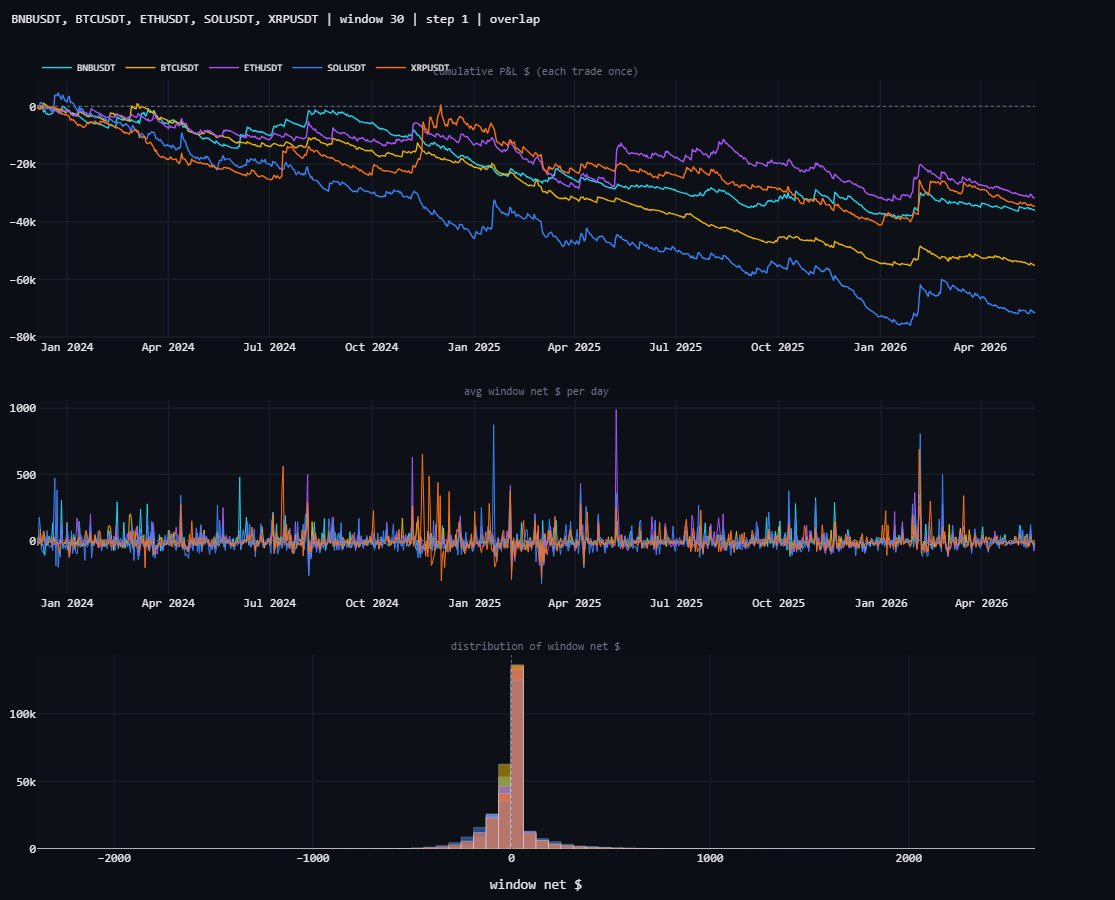

In [34]:
chart.plot_sliding(res).show()

## 6. Inspect one window

Opens the `INSPECT` window with `build_window` - same view as `window_analysis.ipynb`.

In [17]:
r = pick_window(res, INSPECT, INSPECT_SYMBOL)
print(f"{r.symbol} | window {r.window} | candles {r.candles} | {r.start_time} -> {r.end_time} | "
      f"{r.trades} trades | net {r['net_$']:+,.2f}$")
win = build_window(r.symbol, r.start_time.tz_localize(None), WINDOW_SIZE, LEVERAGE, OVERLAP, EMA_SET,
                   stop_loss=STOP_LOSS, trail_step=TRAIL_STEP, take_profit=TAKE_PROFIT, trail_gap=TRAIL_GAP, slope_min=SLOPE_MIN, max_bars=MAX_BARS)
tables.trades(win, MARGIN_USDT)

XRPUSDT | window 194634 | candles 194634-194663 | 2025-10-10 20:25:00+00:00 -> 2025-10-10 22:50:00+00:00 | 30 trades | net +5,083.02$
30 trades | wins 28 | losses 2 | net +5,083.02$ | closed inside window 11, after window 19


,side,entry_time,entry,stop_init,take_profit,trail_steps,exit_time,exit,exit_reason,bars_held,roe,P&L $
1,short,2025-10-10 20:30:00+00:00,2.70,2.76,2.37,4,2025-10-10 21:00:00+00:00,2.50,trail,7,+36.6%,+36.64
2,short,2025-10-10 20:35:00+00:00,2.69,2.75,2.37,4,2025-10-10 21:00:00+00:00,2.50,trail,6,+35.7%,+35.70
3,short,2025-10-10 20:40:00+00:00,2.69,2.75,2.38,4,2025-10-10 21:00:00+00:00,2.50,trail,5,+35.8%,+35.77
4,short,2025-10-10 20:45:00+00:00,2.69,2.75,2.40,4,2025-10-10 21:00:00+00:00,2.50,trail,4,+36.3%,+36.34
5,short,2025-10-10 20:50:00+00:00,2.69,2.75,2.41,4,2025-10-10 21:00:00+00:00,2.50,trail,3,+36.3%,+36.34
6,short,2025-10-10 20:55:00+00:00,2.65,2.72,2.29,3,2025-10-10 21:00:00+00:00,2.50,trail,2,+28.4%,+28.42
7,short,2025-10-10 21:00:00+00:00,2.50,2.65,1.73,4,2025-10-10 21:20:00+00:00,1.95,trail,5,+109.1%,+109.11
8,short,2025-10-10 21:05:00+00:00,2.54,2.72,1.64,4,2025-10-10 21:20:00+00:00,1.97,trail,4,+111.1%,+111.14
9,short,2025-10-10 21:10:00+00:00,2.54,2.72,1.66,4,2025-10-10 21:20:00+00:00,1.97,trail,3,+111.5%,+111.53
10,short,2025-10-10 21:15:00+00:00,2.29,2.58,0.85,1,2025-10-10 21:20:00+00:00,2.08,trail,2,+44.9%,+44.86


In [18]:
tables.rules(win)

EMA test 13_48_200 | momentum: {'BEAR': 30} | state: {'SHORT': 30}


,time,open,high,low,close,EMA 13>48>200,EMA 200>48>13,EMA48 slope,EMA48 not flat,MOMENTUM,ENTRY,STATE
0,10-10 20:25,2.69,2.70,2.69,2.70,✘,✔,-1.21,✔,BEAR,SHORT,SHORT
1,10-10 20:30,2.70,2.70,2.69,2.69,✘,✔,-1.21,✔,BEAR,SHORT,SHORT
2,10-10 20:35,2.69,2.69,2.69,2.69,✘,✔,-1.21,✔,BEAR,SHORT,SHORT
3,10-10 20:40,2.69,2.70,2.69,2.69,✘,✔,-1.23,✔,BEAR,SHORT,SHORT
4,10-10 20:45,2.69,2.70,2.69,2.69,✘,✔,-1.23,✔,BEAR,SHORT,SHORT
5,10-10 20:50,2.69,2.69,2.64,2.65,✘,✔,-1.23,✔,BEAR,SHORT,SHORT
6,10-10 20:55,2.65,2.65,2.41,2.49,✘,✔,-0.84,✔,BEAR,SHORT,SHORT
7,10-10 21:00,2.50,2.54,2.44,2.54,✘,✔,-0.84,✔,BEAR,SHORT,SHORT
8,10-10 21:05,2.54,2.55,2.52,2.54,✘,✔,-0.84,✔,BEAR,SHORT,SHORT
9,10-10 21:10,2.54,2.55,2.20,2.28,✘,✔,-0.79,✔,BEAR,SHORT,SHORT


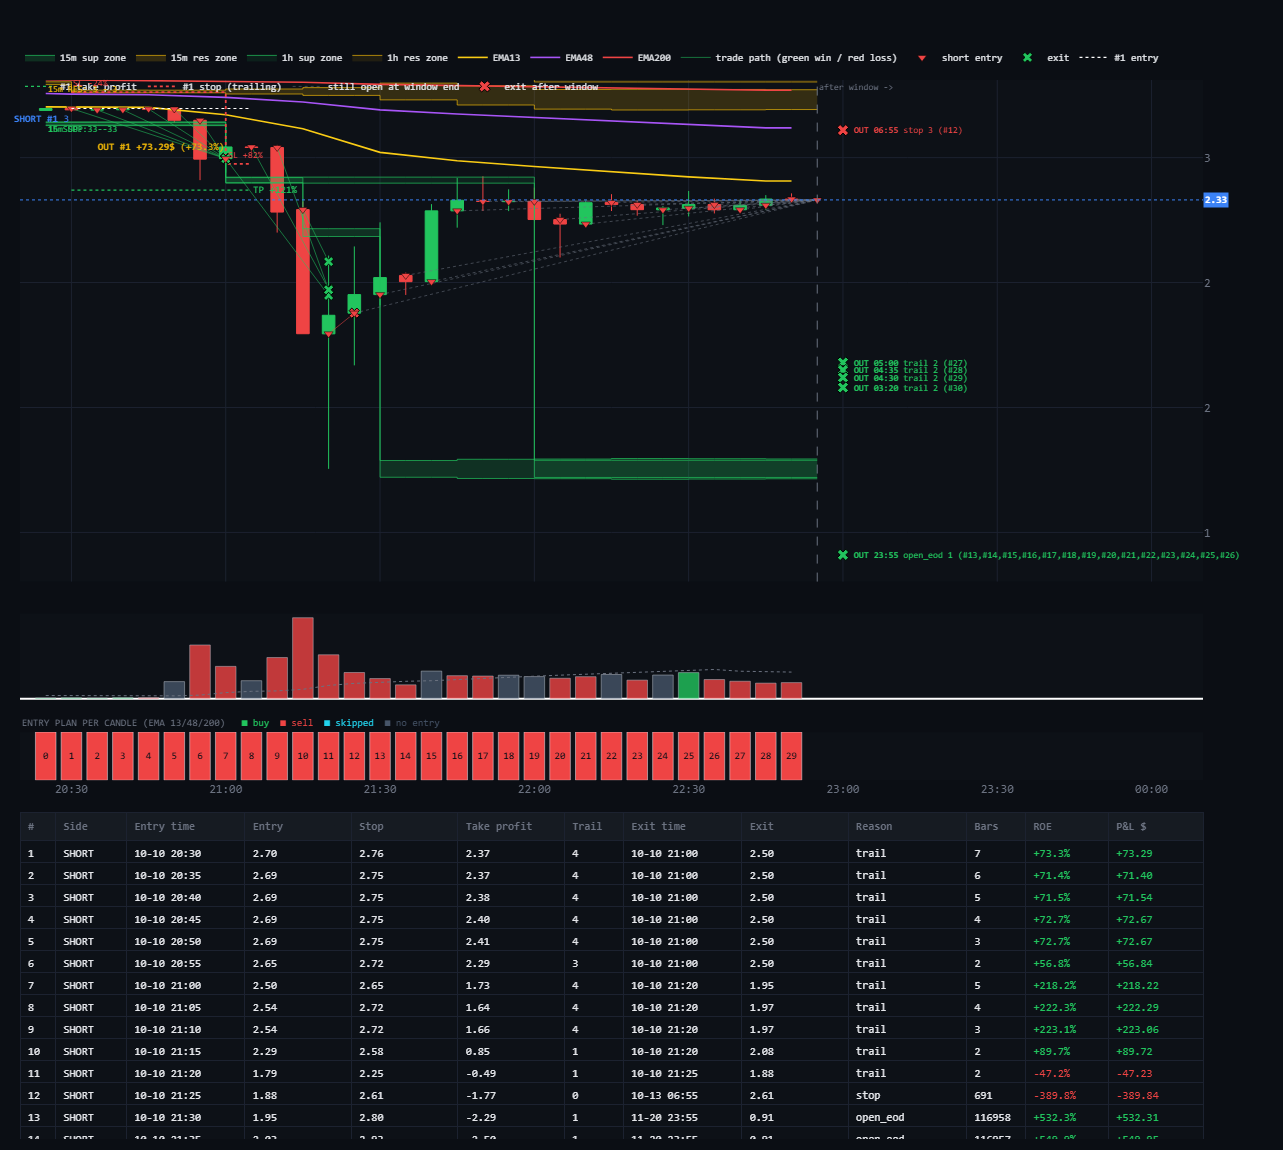

In [9]:
chart.plot_window(win, MARGIN_USDT, SHOW_ZONES, HIGHLIGHT, zoom=ZOOM).show()